# Experiment Challenge: Credit Default Prediction

## Experiment 0 — Data Understanding & Preparation

Import Library

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

Input Data & Membaca Dataset

In [39]:
df = pd.read_csv('/content/UCI_Credit_Card.csv')
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


Dimensi Data

In [40]:
df.shape

(30000, 25)

Dataset terdiri dari 30.000 observasi dan 25 variabel, sesuai dengan karakteristik dataset yang disebutkan pada soal UTS.

Struktur & tipe Data

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

Memeriksa Missing Value

In [42]:
df.isnull().sum()

,0
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0


Tidak terdapat missing value pada dataset sehingga tidak diperlukan imputasi missing value.

Memeriksa Duplicate

In [43]:
df.duplicated().sum()

np.int64(0)

Tidak ditemukan data yang mengalami duplikat sehingga tidak diperlukan penghapusan duplicate.

Memeriksa nilai yang tidak sesuai

In [44]:
categorical_cols = [
    'SEX', 'EDUCATION', 'MARRIAGE',
    'PAY_0', 'PAY_2', 'PAY_3',
    'PAY_4', 'PAY_5', 'PAY_6'
]

summary = pd.DataFrame({
    'Variabel': categorical_cols,
    'Minimum': [df[col].min() for col in categorical_cols],
    'Maksimum': [df[col].max() for col in categorical_cols],
    'Jumlah Nilai Unik': [df[col].nunique() for col in categorical_cols]
})
summary

,Variabel,Minimum,Maksimum,Jumlah Nilai Unik
0,SEX,1,2,2
1,EDUCATION,0,6,7
2,MARRIAGE,0,3,4
3,PAY_0,-2,8,11
4,PAY_2,-2,8,11
5,PAY_3,-2,8,11
6,PAY_4,-2,8,11
7,PAY_5,-2,8,10
8,PAY_6,-2,8,10


In [45]:
# Menyesuaikan kategori yang tidak terdokumentasi
df['EDUCATION'] = df['EDUCATION'].replace({0: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

In [46]:
print("EDUCATION:")
print(df['EDUCATION'].value_counts().sort_index())

print("\nMARRIAGE:")
print(df['MARRIAGE'].value_counts().sort_index())

EDUCATION:
EDUCATION
1    10585
2    14030
3     4917
4      137
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


Pada variabel `EDUCATION` dan `MARRIAGE` ditemukan nilai 0 yang tidak tercantum dalam keterangan kategori dataset. Untuk menyesuaikan kategori dengan keterangannya, nilai 0 pada `EDUCATION` direkode menjadi kategori 4 (others), sedangkan nilai 0 pada MARRIAGE direkode menjadi kategori 3 (others). Sementara itu, nilai 5 dan 6 pada `EDUCATION` tetap dipertahankan sebagai kategori unknown dalam dokumentasi dataset.

Distribusi Target

In [47]:
target = 'default.payment.next.month'
target_dist = pd.DataFrame({
    'Jumlah': df[target].value_counts().sort_index(),
    'Proporsi (%)': df[target].value_counts(normalize=True).sort_index() * 100
})

target_dist.index.name = 'Target'
target_dist

,Jumlah,Proporsi (%)
Target,,
0,23364,77.88
1,6636,22.12


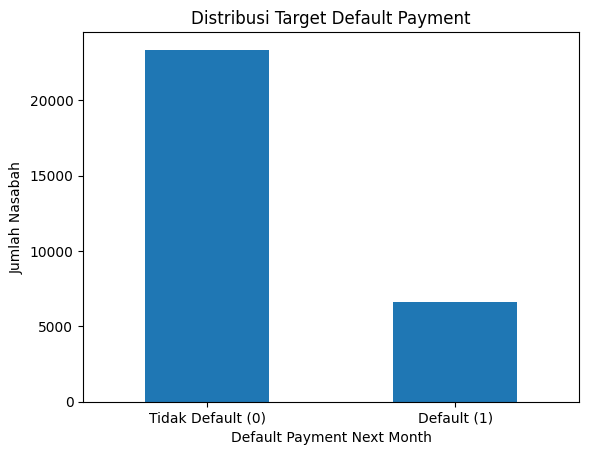

In [48]:
df[target].value_counts().sort_index().plot(
    kind='bar'
)
plt.title('Distribusi Target Default Payment')
plt.xlabel('Default Payment Next Month')
plt.ylabel('Jumlah Nasabah')
plt.xticks(
    ticks=[0, 1],
    labels=['Tidak Default (0)', 'Default (1)'],
    rotation=0
)
plt.show()

Dari hasil pemeriksaan distribusi tersebut, terdapat class imbalance karena kelas 0 jauh lebih banyak dibandingkan kelas 1. Oleh karena itu, eksperimen ini akan melihat Precision, Recall, dan terutama F1-score, bukan hanya Accuracy.

Menentukan Predictor dan Target

In [49]:
y = df['default.payment.next.month']

In [50]:
X = df.drop(columns=['ID', 'default.payment.next.month'])
y = df['default.payment.next.month']

print("Dimensi X:", X.shape)
print("Dimensi y:", y.shape)

Dimensi X: (30000, 23)
Dimensi y: (30000,)


Terdapat 1 target yaitu `default.payment.next.month` dan 23 predictor dengan `ID` dikeluarkan dari predictor.

Train-test Split

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (24000, 23)
X_test : (6000, 23)
y_train: (24000,)
y_test : (6000,)


## Kesimpulan
Dataset terdiri dari 30.000 observasi dan 25 variabel, tanpa missing value maupun duplicate. Target default.payment.next.month menunjukkan ketidakseimbangan kelas, yaitu 77,88% kelas 0 dan 22,12% kelas 1, sehingga F1-score digunakan sebagai metrik utama. Nilai 0 pada `EDUCATION` dan `MARRIAGE` direkode masing-masing menjadi kategori others, sedangkan ID dikeluarkan dari predictor. Data kemudian dibagi menjadi 80% data training dan 20% data testing menggunakan stratified split dengan random_state=42.

## Experiment 1 — Baseline Model

In [52]:
logreg = LogisticRegression(
    max_iter=8000,
    random_state=42
)

logreg.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=8000, random_state=42)

Model baseline belum konvergen karena fitur belum discaling sehingga skala LIMIT_BAL dan BILL_AMT sangat berbeda dari PAY_x. Pada Experiment 2 akan dilakukan feature scaling dengan StandardScaler.

In [53]:
cv_f1 = cross_val_score(
    logreg,
    X_train,
    y_train,
    cv=5,
    scoring='f1'
)

print("F1-score setiap fold:", cv_f1)
print("Mean CV F1-score:", cv_f1.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

F1-score setiap fold: [0.36174636 0.38888889 0.35219236 0.3771273  0.37196391]
Mean CV F1-score: 0.37038376483170593


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [54]:
cv_result = pd.DataFrame({
    'Fold': range(1, 6),
    'F1-score': cv_f1
})

cv_result.loc[len(cv_result)] = ['Mean', cv_f1.mean()]
cv_result

,Fold,F1-score
0,1,0.361746
1,2,0.388889
2,3,0.352192
3,4,0.377127
4,5,0.371964
5,Mean,0.370384


In [55]:
y_pred = logreg.predict(X_test)

test_result = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ]
})

test_result

,Metric,Score
0,Accuracy,0.807667
1,Precision,0.685225
2,Recall,0.241145
3,F1-score,0.356745


In [56]:
exp1_result = pd.DataFrame({
    'Experiment': ['Experiment 1'],
    'Model': ['Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, y_pred)],
    'Precision': [precision_score(y_test, y_pred)],
    'Recall': [recall_score(y_test, y_pred)],
    'F1-score': [f1_score(y_test, y_pred)],
    'CV F1-score': [cv_f1.mean()]
})

exp1_result

,Experiment,Model,Accuracy,Precision,Recall,F1-score,CV F1-score
0,Experiment 1,Logistic Regression,0.807667,0.685225,0.241145,0.356745,0.370384


Hasil baseline Logistic Regression menunjukkan CV F1-score sebesar 0,3703 dan Test F1-score sebesar 0,3567. Accuracy sebesar 0,8076 terlihat cukup tinggi, tetapi belum cukup menunjukkan kemampuan model dalam mendeteksi nasabah yang default karena kelas 0 lebih dominan. Hal tersebut terlihat dari recall yang hanya sebesar 0,241, sehingga masih banyak nasabah default yang belum berhasil dideteksi oleh model. Nilai CV F1 dan Test F1 yang cukup dekat menunjukkan bahwa hasil model pada data training dan testing cukup konsisten.


# Experiment 2 — Preprocessing

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [60]:
cv_f1_scaled = cross_val_score(
    logreg_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='f1'
)

cv_result_exp2 = pd.DataFrame({
    'Fold': range(1, 6),
    'F1-score': cv_f1_scaled
})

cv_result_exp2.loc[len(cv_result_exp2)] = [
    'Mean',
    cv_f1_scaled.mean()
]

cv_result_exp2

,Fold,F1-score
0,1,0.357836
1,2,0.378264
2,3,0.375350
3,4,0.361613
4,5,0.356841
5,Mean,0.365981


Hasil 5-fold cross validation menghasilkan F1-score rata-rata sebesar 0,3660. Nilai antarfold cukup dekat yang menunjukkan performa model pada masing-masing fold cukup konsisten. Nilai rata-rata CV F1-score digunakan sebagai ukuran performa model selama validasi pada data training.

In [64]:
logreg_pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logreg', LogisticRegression(max_iter=1000, random_state=42))])

In [65]:
y_pred_scaled = logreg_pipeline.predict(X_test)

exp2_result = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [
        accuracy_score(y_test, y_pred_scaled),
        precision_score(y_test, y_pred_scaled),
        recall_score(y_test, y_pred_scaled),
        f1_score(y_test, y_pred_scaled)
    ]
})

exp2_result

,Metric,Score
0,Accuracy,0.808000
1,Precision,0.686567
2,Recall,0.242653
3,F1-score,0.358575


Pada data testing, model menghasilkan accuracy 0,808, precision 0,6865, recall 0,2426, dan F1-score 0,3585. Nilai recall dan F1-score yang masih rendah menunjukkan bahwa model belum optimal dalam mendeteksi nasabah yang mengalami default.

In [66]:
exp2_result = pd.DataFrame({
    'Experiment': ['Experiment 2'],
    'Model': ['Logistic Regression + Scaling'],
    'Accuracy': [accuracy_score(y_test, y_pred_scaled)],
    'Precision': [precision_score(y_test, y_pred_scaled)],
    'Recall': [recall_score(y_test, y_pred_scaled)],
    'F1-score': [f1_score(y_test, y_pred_scaled)],
    'CV F1-score': [cv_f1_scaled.mean()]
})

final_exp_result = pd.concat(
    [exp1_result, exp2_result],
    ignore_index=True
)

final_exp_result

,Experiment,Model,Accuracy,Precision,Recall,F1-score,CV F1-score
0,Experiment 1,Logistic Regression,0.807667,0.685225,0.241145,0.356745,0.370384
1,Experiment 2,Logistic Regression + Scaling,0.808000,0.686567,0.242653,0.358575,0.365981


In [67]:
comparison_exp1_exp2 = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'CV F1-score'],
    'Experiment 1': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        cv_f1.mean()
    ],
    'Experiment 2': [
        accuracy_score(y_test, y_pred_scaled),
        precision_score(y_test, y_pred_scaled),
        recall_score(y_test, y_pred_scaled),
        f1_score(y_test, y_pred_scaled),
        cv_f1_scaled.mean()
    ]
})

comparison_exp1_exp2['Perubahan'] = (
    comparison_exp1_exp2['Experiment 2'] -
    comparison_exp1_exp2['Experiment 1']
)

comparison_exp1_exp2

,Metric,Experiment 1,Experiment 2,Perubahan
0,Accuracy,0.807667,0.808000,0.000333
1,Precision,0.685225,0.686567,0.001342
2,Recall,0.241145,0.242653,0.001507
3,F1-score,0.356745,0.358575,0.001830
4,CV F1-score,0.370384,0.365981,-0.004403


Berdasarkan perubahan metrik, F1-score pada test set meningkat sebesar 0,001830, sedangkan accuracy, precision, dan recall masing-masing meningkat sebesar 0,000333, 0,001342, dan 0,001507. Namun, CV F1-score mengalami penurunan sebesar 0,004403. Karena F1-score merupakan metrik utama, kenaikan F1-score pada test set menunjukkan adanya perbaikan, meskipun nilainya sangat kecil. Akan tetapi CV F1-score yang menurun menunjukkan bahwa peningkatan tersebut belum cukup konsisten pada hasil cross validation.

Secara keseluruhan, feature scaling belum memberikan peningkatan performa yang konsisten pada Logistic Regression. Meskipun F1-score pada test set-nya naik, CV F1-score justru menurun.

# Experiment 3 — Model Comparison

In [68]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [69]:
models = {
    'Logistic Regression': logreg_pipeline,
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

In [70]:
cv_results = []

for name, model in models.items():
    cv_f1 = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='f1'
    )

    cv_results.append({
        'Model': name,
        'CV F1-score': cv_f1.mean()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,Model,CV F1-score
0,Logistic Regression,0.365981
1,Decision Tree,0.407819
2,Random Forest,0.469620


In [71]:
cv_detail = []

for name, model in models.items():
    cv_f1 = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='f1'
    )

    for i, score in enumerate(cv_f1, start=1):
        cv_detail.append({
            'Model': name,
            'Fold': i,
            'F1-score': score
        })

cv_detail_df = pd.DataFrame(cv_detail)
cv_detail_df

,Model,Fold,F1-score
0,Logistic Regression,1,0.357836
1,Logistic Regression,2,0.378264
2,Logistic Regression,3,0.375350
3,Logistic Regression,4,0.361613
4,Logistic Regression,5,0.356841
5,Decision Tree,1,0.419194
6,Decision Tree,2,0.403695
7,Decision Tree,3,0.432384
8,Decision Tree,4,0.387534
9,Decision Tree,5,0.396288


In [72]:
test_results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    test_results.append({
        'Model': name,
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test Precision': precision_score(y_test, y_pred),
        'Test Recall': recall_score(y_test, y_pred),
        'Test F1-score': f1_score(y_test, y_pred)
    })

test_results_df = pd.DataFrame(test_results)
test_results_df

,Model,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,Logistic Regression,0.808000,0.686567,0.242653,0.358575
1,Decision Tree,0.709833,0.359375,0.398644,0.377992
2,Random Forest,0.812500,0.634309,0.359457,0.458874


In [97]:
exp3_result = test_results_df.merge(
    cv_results_df,
    on='Model'
)

exp3_result = exp3_result[
    ['Model', 'Test Accuracy', 'Test Precision',
     'Test Recall', 'Test F1-score', 'CV F1-score']
]

exp3_result

,Model,Test Accuracy,Test Precision,Test Recall,Test F1-score,CV F1-score
0,Logistic Regression,0.808000,0.686567,0.242653,0.358575,0.365981
1,Decision Tree,0.709833,0.359375,0.398644,0.377992,0.407819
2,Random Forest,0.812500,0.634309,0.359457,0.458874,0.469620


Berdasarkan hasil perbandingan, Random Forest memiliki performa terbaik dibandingkan Logistic Regression dan Decision Tree. Random Forest memperoleh CV F1-score sebesar 0.4696 dan Test F1-score sebesar 0,4589, yang merupakan nilai tertinggi di antara ketiga model. Meskipun precision Random Forest lebih rendah dibandingkan Logistic Regression, nilai recallnya lebih tinggi sehingga nilai F1-score lebih baik. Oleh karena itu, Random Forest dipilih sebagai model terbaik untuk digunakan pada Experiment 4, yaitu hyperparameter tuning.

#Experiment 4 — Hyperparameter Tuning

In [98]:
rf_before = exp3_result[
    exp3_result['Model'] == 'Random Forest'
].iloc[0]

In [99]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': [None, 'balanced']
}

Beberapa hyperparameter Random Forest diuji menggunakan GridSearchCV dengan 5-fold cross validation untuk mencari kombinasi yang memberikan F1-score terbaik.

In [75]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(
    random_state=42
)

In [76]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'class_weight': [None, 'balanced'],
                         'max_depth': [None, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100]},
             return_train_score=True, scoring='f1')

In [100]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1-score:")
print(grid_search.best_score_)

Best Parameters:
{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}

Best CV F1-score:
0.5444199899953107


Berdasarkan hasil GridSearchCV, kombinasi hyperparameter terbaik terdiri dari `class_weight='balanced'`, `max_depth=10`, `min_samples_leaf=2`, `min_samples_split=2`, dan `n_estimators=100`. Kombinasi tersebut menghasilkan CV F1-score sebesar 0,5444 dan selanjutnya digunakan pada Random Forest setelah tuning..

In [78]:
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results = grid_results[
    [
        'param_n_estimators',
        'param_max_depth',
        'param_min_samples_split',
        'param_min_samples_leaf',
        'param_class_weight',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
].sort_values('rank_test_score')

grid_results.head(10)

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score,rank_test_score
37,100,10,2,2,balanced,0.544420,0.005735,1
39,100,10,5,2,balanced,0.543110,0.003200,2
33,100,10,2,1,balanced,0.542841,0.005260,3
32,50,10,2,1,balanced,0.542697,0.005508,4
34,50,10,5,1,balanced,0.542558,0.006270,5
35,100,10,5,1,balanced,0.542297,0.005669,6
36,50,10,2,2,balanced,0.541568,0.004449,7
38,50,10,5,2,balanced,0.541097,0.005639,8
47,100,20,5,2,balanced,0.519506,0.009281,9
46,50,20,5,2,balanced,0.515810,0.008094,10


In [79]:
best_rf = grid_search.best_estimator_

In [80]:
y_pred_tuned = best_rf.predict(X_test)

In [81]:
tuned_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score'
    ],
    'Score': [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned)
    ]
})

tuned_results

,Metric,Score
0,Accuracy,0.788667
1,Precision,0.520415
2,Recall,0.566692
3,F1-score,0.542569


In [101]:
exp_4_results = pd.DataFrame({
    'Model': ['Random Forest Tuned'],
    'Test Accuracy': [accuracy_score(y_test, y_pred_tuned)],
    'Test Precision': [precision_score(y_test, y_pred_tuned)],
    'Test Recall': [recall_score(y_test, y_pred_tuned)],
    'Test F1-score': [f1_score(y_test, y_pred_tuned)],
    'CV F1-score': [grid_search.best_score_]
})

exp_4_results

,Model,Test Accuracy,Test Precision,Test Recall,Test F1-score,CV F1-score
0,Random Forest Tuned,0.788667,0.520415,0.566692,0.542569,0.54442


In [102]:
comparison_tuning = pd.DataFrame({
    'Metric': [
        'Test Accuracy',
        'Test Precision',
        'Test Recall',
        'Test F1-score',
        'CV F1-score'
    ],
    'Sebelum Tuning': [
        rf_before['Test Accuracy'],
        rf_before['Test Precision'],
        rf_before['Test Recall'],
        rf_before['Test F1-score'],
        rf_before['CV F1-score']
    ],
    'Setelah Tuning': [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned),
        grid_search.best_score_
    ]
})

comparison_tuning['Perubahan'] = (
    comparison_tuning['Setelah Tuning']
    - comparison_tuning['Sebelum Tuning']
)

comparison_tuning

,Metric,Sebelum Tuning,Setelah Tuning,Perubahan
0,Test Accuracy,0.812500,0.788667,-0.023833
1,Test Precision,0.634309,0.520415,-0.113893
2,Test Recall,0.359457,0.566692,0.207234
3,Test F1-score,0.458874,0.542569,0.083694
4,CV F1-score,0.469620,0.544420,0.074800


Hasil perbandingan menunjukkan bahwa hyperparameter tuning meningkatkan performa Random Forest berdasarkan metrik utama F1-score. Test F1-score meningkat dari 0,4589 menjadi 0.5426, sedangkan CV F1-score meningkat dari 0,4696 menjadi 0,5444. Selain itu, recall juga meningkat dari 0,3594 menjadi 0,5667, sehingga model lebih mampu mendeteksi nasabah yang mengalami default. Namun, accuracy menurun dari 0,8125 menjadi 0,7887 dan precision dari 0,6343 menjadi 0,5204. Karena F1-score merupakan metrik utama dalam penelitian ini, hasil tuning menunjukkan adanya peningkatan performa Random Forest secara keseluruhan.

In [95]:
rf_tuned_result = {
    'Test Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Test Precision': precision_score(y_test, y_pred_tuned),
    'Test Recall': recall_score(y_test, y_pred_tuned),
    'Test F1-score': f1_score(y_test, y_pred_tuned),
    'CV F1-score': grid_search.best_score_
}

#Experiment 5 — Advanced Model

In [84]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

gb_model = GradientBoostingClassifier(
    random_state=42
)

In [85]:
cv_f1_gb = cross_val_score(
    gb_model,
    X_train,
    y_train,
    cv=5,
    scoring='f1'
)

cv_result_exp5 = pd.DataFrame({
    'Fold': range(1, 6),
    'F1-score': cv_f1_gb
})

cv_result_exp5.loc[len(cv_result_exp5)] = [
    'Mean',
    cv_f1_gb.mean()
]

cv_result_exp5

,Fold,F1-score
0,1,0.480676
1,2,0.488344
2,3,0.466830
3,4,0.488862
4,5,0.465059
5,Mean,0.477954


Hasil 5-fold cross validation pada Gradient Boosting menghasilkan rata-rata CV F1-score sebesar 0,4779.

In [86]:
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [87]:
y_pred_gb = gb_model.predict(X_test)

exp5_result = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [
        accuracy_score(y_test, y_pred_gb),
        precision_score(y_test, y_pred_gb),
        recall_score(y_test, y_pred_gb),
        f1_score(y_test, y_pred_gb)
    ]
})

exp5_result

,Metric,Score
0,Accuracy,0.818500
1,Precision,0.665738
2,Recall,0.360211
3,F1-score,0.467482


In [94]:
gb_exp5_result = {
    'Test Accuracy': accuracy_score(y_test, y_pred_gb),
    'Test Precision': precision_score(y_test, y_pred_gb),
    'Test Recall': recall_score(y_test, y_pred_gb),
    'Test F1-score': f1_score(y_test, y_pred_gb),
    'CV F1-score': cv_f1_gb.mean()
}

In [96]:
comparison_exp4_exp5 = pd.DataFrame({
    'Metric': [
        'Test Accuracy',
        'Test Precision',
        'Test Recall',
        'Test F1-score',
        'CV F1-score'
    ],
    'Random Forest + Tuning': [
        rf_tuned_result['Test Accuracy'],
        rf_tuned_result['Test Precision'],
        rf_tuned_result['Test Recall'],
        rf_tuned_result['Test F1-score'],
        rf_tuned_result['CV F1-score']
    ],
    'Gradient Boosting': [
        gb_exp5_result['Test Accuracy'],
        gb_exp5_result['Test Precision'],
        gb_exp5_result['Test Recall'],
        gb_exp5_result['Test F1-score'],
        gb_exp5_result['CV F1-score']
    ]
})

comparison_exp4_exp5

,Metric,Random Forest + Tuning,Gradient Boosting
0,Test Accuracy,0.788667,0.818500
1,Test Precision,0.520415,0.665738
2,Test Recall,0.566692,0.360211
3,Test F1-score,0.542569,0.467482
4,CV F1-score,0.544420,0.477954


Berdasarkan hasil perbandingan, Gradient Boosting memiliki accuracy dan precision yang lebih tinggi dibandingkan Random Forest setelah tuning yaitu sebesar 0,8185 dan 0,6657. Namun, CV F1-score dan Test F1-score Gradient Boosting lebih rendah, yaitu masing-masing 0,4780 dan 0,4675 dibandingkan 0,5444 dan 0,5426 pada Random Forest setelah tuning. Recall Gradient Boosting juga lebih rendah, yaitu 0,3602 dibandingkan 0,5667. Karena F1-score merupakan metrik utama, Random Forest setelah tuning tetap memberikan performa yang lebih baik.

# Summary of Experiment Results

In [104]:
final_summary = pd.DataFrame({
    'Experiment': [
        'Experiment 1',
        'Experiment 2',
        'Experiment 3',
        'Experiment 4',
        'Experiment 5'
    ],

    'Model': [
        'Logistic Regression',
        'Logistic Regression + Scaling',
        'Random Forest',
        'Random Forest + Tuning',
        'Gradient Boosting'
    ],

    'CV F1': [
        exp1_result['CV F1-score'].iloc[0],
        exp2_result['CV F1-score'].iloc[0],
        rf_before['CV F1-score'],
        rf_tuned_result['CV F1-score'],
        gb_exp5_result['CV F1-score']
    ],

    'Test Accuracy': [
        exp1_result['Accuracy'].iloc[0],
        exp2_result['Accuracy'].iloc[0],
        rf_before['Test Accuracy'],
        rf_tuned_result['Test Accuracy'],
        gb_exp5_result['Test Accuracy']
    ],

    'Test Precision': [
        exp1_result['Precision'].iloc[0],
        exp2_result['Precision'].iloc[0],
        rf_before['Test Precision'],
        rf_tuned_result['Test Precision'],
        gb_exp5_result['Test Precision']
    ],

    'Test Recall': [
        exp1_result['Recall'].iloc[0],
        exp2_result['Recall'].iloc[0],
        rf_before['Test Recall'],
        rf_tuned_result['Test Recall'],
        gb_exp5_result['Test Recall']
    ],

    'Test F1': [
        exp1_result['F1-score'].iloc[0],
        exp2_result['F1-score'].iloc[0],
        rf_before['Test F1-score'],
        rf_tuned_result['Test F1-score'],
        gb_exp5_result['Test F1-score']
    ]
})

final_summary

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Experiment 1,Logistic Regression,0.370384,0.807667,0.685225,0.241145,0.356745
1,Experiment 2,Logistic Regression + Scaling,0.365981,0.808000,0.686567,0.242653,0.358575
2,Experiment 3,Random Forest,0.469620,0.812500,0.634309,0.359457,0.458874
3,Experiment 4,Random Forest + Tuning,0.544420,0.788667,0.520415,0.566692,0.542569
4,Experiment 5,Gradient Boosting,0.477954,0.818500,0.665738,0.360211,0.467482


Berdasarkan hasil seluruh eksperimen, performa model mengalami perubahan pada setiap tahap. Logistic Regression pada Experiment 1 memiliki Test F1-score sebesar 0,3567, kemudian setelah scaling pada Experiment 2 meningkat sedikit menjadi 0,3586, meskipun CV F1-score turun dari 0,3704 menjadi 0,3660. Pada Experiment 3, Random Forest memberikan peningkatan performa dengan Test F1-score sebesar 0,4589 dan CV F1-score sebesar 0,4696. Setelah dilakukan hyperparameter tuning pada Experiment 4, Test F1-score meningkat menjadi 0,5426 dan CV F1-score menjadi 0,5444, yang merupakan hasil terbaik dari seluruh eksperimen. Sementara itu, Gradient Boosting pada Experiment 5 memiliki Test F1-score sebesar 0,4675 dan CV F1-score sebesar 0,4780 yang lebih kecil dibandingkan Random Forest setelah tuning. Meskipun Gradient Boosting memiliki Test Accuracy tertinggi sebesar 0,8185, F1-score sebagai metrik utama menunjukkan bahwa Random Forest setelah tuning merupakan model terbaik dan dipilih sebagai model final.